# Preprocessing dan Feature Engineering

Tahap ini memperbaiki baris suspensi yang ditemukan pada EDA, menyesuaikan harga terhadap stock split, menghitung indikator teknikal, dan membentuk target return hari bursa berikutnya.

In [1]:
# import library
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import sys
# biar file .py di folder utama bisa di-import dari folder notebooks
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline_utils import adjust_prices_for_splits, attach_calendar_targets, show_table

from notebook_config import (
    palette,
    blue,
    configure_notebook,
    feature_columns as features,
    green,
    light,
    orange,
    red,
    target,
    tickers,
)

In [2]:
# mengatur folder input dan output, kolom kunci, dan gaya grafik
root_dir, output_dir = configure_notebook()
interim_dir = root_dir / "data" / "interim"
processed_dir = root_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
key_columns = ["Kode Saham", "snapshot_date"]
price_columns = ["Open Price", "Tertinggi", "Terendah", "Penutupan"]

plt.rcParams["figure.dpi"] = 120

plt.rcParams["font.family"] = "DejaVu Sans"

# nama kolom yang ditampilkan di tabel
display_names = {
    "snapshot_date": "Tanggal",
    "target_date": "Tanggal Target",
    "Kode Saham": "Ticker",
    "close_adj": "Adjusted Close",
    "simple_return": "Simple Return",
    "target_next_return": "Target Return",
    "SMA10": "SMA 10",
    "SMA20": "SMA 20",
    "EMA10": "EMA 10",
    "RSI14": "RSI 14",
    "Signal": "MACD Signal",
    "BB_Upper": "Bollinger Upper",
    "BB_Lower": "Bollinger Lower",
    "Stochastic_%K": "Stochastic %K",
    "ATR14": "ATR 14"
}

## Load Data

In [3]:
# membaca data hasil notebook 01 dan mengambil 11 saham penelitian
raw_data = pd.read_parquet(interim_dir / "panel_raw.parquet")
raw_df = raw_data.loc[raw_data["Kode Saham"].isin(tickers)].copy()
raw_df = raw_df.sort_values(key_columns, kind="stable").reset_index(drop=True)
required_columns = key_columns + price_columns + ["Volume", "Listed Shares"]
# jumlah baris awal tiap saham
show_table(raw_df.groupby("Kode Saham").size().rename("Baris awal").to_frame())

panel = raw_df.copy()

,Baris awal
Kode Saham,
BBCA,"1,447"
BBNI,"1,447"
BBRI,"1,447"
BBTN,"1,447"
BDMN,"1,447"
BJBR,"1,447"
BMRI,"1,447"
BNGA,"1,447"
BNLI,"1,447"


## Mengisi Data

Tahap EDA sebelumnya menemukan OHLV bernilai nol pada emiten BNLI pada tanggal 2025-09-30. Data OHL pada hari tersebut diisi dengan Close hari sebelumnya, sedangkan Volume di pertahankan karena memang tidak terdapat perdagangan.

In [4]:
# baris suspensi itu volume nol, OHL nol, dan close sama dengan kemarin
# memperbaiki baris suspensi yang ketemu di EDA (BNLI 30-09-2025)
previous_close = raw_df.groupby("Kode Saham")["Penutupan"].shift(1)
zero_volume = raw_df["Volume"].eq(0)
zero_ohl = raw_df[["Open Price", "Tertinggi", "Terendah"]].eq(0).all(axis=1)
suspension_rows = zero_volume & zero_ohl & raw_df["Penutupan"].eq(previous_close)

view_columns = key_columns + price_columns + ["Volume"]

repair_before = raw_df.loc[suspension_rows, view_columns].copy()

# mengisi OHLC pakai close kemarin, volume tetap nol
for column in price_columns:
    raw_df.loc[suspension_rows, column] = previous_close.loc[suspension_rows]

repair_after = raw_df.loc[suspension_rows, view_columns].copy()

# membandingkan sebelum dan sesudah diperbaiki
print("Baris suspensi - SEBELUM OHLC diisi")
show_table(repair_before, display_names=display_names)

print("Baris suspensi - SETELAH OHLC diisi")
show_table(repair_after, display_names=display_names)

calendar_raw_df = raw_df.copy()
# mengecek tidak ada saham dan tanggal yang dobel
assert not raw_df.duplicated(key_columns).any()

Baris suspensi - SEBELUM OHLC diisi


,Ticker,Tanggal,Open Price,Tertinggi,Terendah,Penutupan,Volume
12959,BNLI,2025-09-30,0,0,0,"5,950",0


Baris suspensi - SETELAH OHLC diisi


,Ticker,Tanggal,Open Price,Tertinggi,Terendah,Penutupan,Volume
12959,BNLI,2025-09-30,"5,950","5,950","5,950","5,950",0


## Menyesuaikan Harga Stock Split

Rasio perubahan Listed Shares yang berupa faktor bulat ditandai sebagai stock split. Harga sebelum tanggal split dikalikan faktor kebalikannya secara mundur, sedangkan volume dikalikan rasio saham.

In [5]:
# menyesuaikan harga kalau ada stock split, dilihat dari rasio Listed Shares
# fungsinya ada di pipeline_utils.py
# harga sebelum split dibagi rasio split, volume dikali rasio split
# hasilnya kolom *_adj dan simple_return
calendar_data, split_events = adjust_prices_for_splits(
    calendar_raw_df,
    ticker_col="Kode Saham",
    date_col="snapshot_date",
    listed_shares_col="Listed Shares",
    price_columns={
        "Open Price": "open_adj",
        "Tertinggi": "high_adj",
        "Terendah": "low_adj",
        "Penutupan": "close_adj",
    },
    volume_col="Volume",
)

df = calendar_data.copy()
# daftar stock split yang ketemu
show_table(
    split_events,
    display_names={
        "Kode Saham": "Ticker",
        "snapshot_date": "Tanggal split",
        "listed_shares_ratio": "Rasio Listed Shares",
    },
)

# kolom yang disimpan ke file kalender harga
calendar_columns = (
    key_columns
    + price_columns
    + [
        "Volume",
        "Listed Shares",
        "listed_shares_ratio",
        "price_adj_factor",
        "volume_adj_factor",
        "open_adj",
        "high_adj",
        "low_adj",
        "close_adj",
        "volume_adj",
        "simple_return",
    ]
)
calendar_data = calendar_data[calendar_columns].copy()
df = calendar_data.copy()

# menyimpan kalender harga, dipakai notebook 03 sampai 05 dan aplikasi
calendar_data.to_parquet(processed_dir / "panel_calendar.parquet", index=False)
calendar_data[
    key_columns
    + price_columns
    + ["Volume", "price_adj_factor", "volume_adj_factor", "close_adj", "volume_adj"]
].to_parquet(processed_dir / "panel_adjusted_prices.parquet", index=False)


,Ticker,Tanggal split,Rasio Listed Shares
0,BBCA,2021-10-13,5
1,BBNI,2023-10-06,2
2,BMRI,2023-04-04,2


## Feature Engineering Indikator Teknikal

Indikator dihitung per saham dengan harga Tertinggi, Terendah, dan Penutupan yang telah disesuaikan terhadap stock split. Setiap indikator menggunakan data sampai tanggal pengamatan.

In [6]:
# fungsi buat menghitung 10 indikator teknikal untuk satu saham
# SMA10, SMA20, EMA10, RSI14, MACD, Signal, BB_Upper, BB_Lower, Stochastic_%K, ATR14
# fungsi ini juga disalin ke feature_pipeline.py biar aplikasi hitungnya sama persis
def compute_technical_indicators(group_df):
    # mengurutkan data saham berdasarkan tanggal sebelum menghitung indikator
    stock_data = group_df.copy().sort_values("snapshot_date").reset_index(drop=True)
    close_values = stock_data["close_adj"].values
    high_values = stock_data["high_adj"].values
    low_values = stock_data["low_adj"].values
    observation_count = len(close_values)

    # menghitung SMA dari 10 dan 20 observasi terakhir
    stock_data["SMA10"] = stock_data["close_adj"].rolling(10).mean()
    stock_data["SMA20"] = stock_data["close_adj"].rolling(20).mean()

    # mean sepuluh close pertama sebagai nilai awal EMA 10
    ema10 = np.full(observation_count, np.nan)
    ema10_alpha = 2.0 / 11.0
    for i in range(observation_count):
        if i < 9:
            continue
        elif i == 9:
            ema10[i] = np.mean(close_values[:10])
        else:
            ema10[i] = close_values[i] * ema10_alpha + ema10[i - 1] * (
                1.0 - ema10_alpha
            )
    stock_data["EMA10"] = ema10

    # menghitung nilai awal RSI, lalu melanjutkan dengan Wilder smoothing
    change = np.diff(close_values, prepend=np.nan)
    gain = np.where(change > 0, change, 0.0)
    loss = np.where(change < 0, -change, 0.0)
    average_gain = np.full(observation_count, np.nan)
    average_loss = np.full(observation_count, np.nan)
    rsi14 = np.full(observation_count, np.nan)
    if observation_count >= 15:
        average_gain[14] = np.mean(gain[1:15])
        average_loss[14] = np.mean(loss[1:15])
        relative_strength = (
            average_gain[14] / average_loss[14] if average_loss[14] != 0 else np.nan
        )
        rsi14[14] = 100.0 - 100.0 / (1.0 + relative_strength)
        for i in range(15, observation_count):
            average_gain[i] = (average_gain[i - 1] * 13.0 + gain[i]) / 14.0
            average_loss[i] = (average_loss[i - 1] * 13.0 + loss[i]) / 14.0
            relative_strength = (
                average_gain[i] / average_loss[i] if average_loss[i] != 0 else np.nan
            )
            rsi14[i] = 100.0 - 100.0 / (1.0 + relative_strength)
    stock_data["RSI14"] = rsi14

    # menghitung EMA 12 dan EMA 26 untuk MACD
    ema12 = np.full(observation_count, np.nan)
    ema12_alpha = 2.0 / 13.0
    for i in range(observation_count):
        if i < 11:
            continue
        elif i == 11:
            ema12[i] = np.mean(close_values[:12])
        else:
            ema12[i] = close_values[i] * ema12_alpha + ema12[i - 1] * (
                1.0 - ema12_alpha
            )

    ema26 = np.full(observation_count, np.nan)
    ema26_alpha = 2.0 / 27.0
    for i in range(observation_count):
        if i < 25:
            continue
        elif i == 25:
            ema26[i] = np.mean(close_values[:26])
        else:
            ema26[i] = close_values[i] * ema26_alpha + ema26[i - 1] * (
                1.0 - ema26_alpha
            )

    stock_data["MACD"] = ema12 - ema26

    # memulai signal dari mean sembilan nilai MACD pertama
    signal = np.full(observation_count, np.nan)
    signal_alpha = 2.0 / 10.0
    valid_macd_idx = [
        i for i in range(observation_count) if not np.isnan(stock_data["MACD"].iloc[i])
    ]
    if len(valid_macd_idx) >= 9:
        start_sig = valid_macd_idx[8]
        signal[start_sig] = np.mean(
            [stock_data["MACD"].iloc[k] for k in valid_macd_idx[:9]]
        )
        for i in range(start_sig + 1, observation_count):
            signal[i] = stock_data["MACD"].iloc[i] * signal_alpha + signal[i - 1] * (
                1.0 - signal_alpha
            )
    stock_data["Signal"] = signal

    # menghitung Bollinger Bands dengan standard deviation populasi
    std20 = (
        stock_data["close_adj"].rolling(20).apply(lambda x: np.std(x, ddof=0), raw=True)
    )
    stock_data["BB_Upper"] = stock_data["SMA20"] + 2.0 * std20
    stock_data["BB_Lower"] = stock_data["SMA20"] - 2.0 * std20

    # memakai nilai 50 pada Stochastic %K jika rentang harga nol
    lowest_14 = stock_data["low_adj"].rolling(14).min()
    highest_14 = stock_data["high_adj"].rolling(14).max()
    price_range = highest_14 - lowest_14
    stock_data["Stochastic_%K"] = np.where(
        price_range != 0,
        (stock_data["close_adj"] - lowest_14) / price_range * 100.0,
        50.0,
    )

    # menghitung true range, lalu ATR 14 dengan Wilder smoothing
    true_range = np.full(observation_count, np.nan)
    for i in range(1, observation_count):
        true_range[i] = max(
            high_values[i] - low_values[i],
            abs(high_values[i] - close_values[i - 1]),
            abs(low_values[i] - close_values[i - 1]),
        )
    atr14 = np.full(observation_count, np.nan)
    if observation_count >= 15:
        atr14[14] = np.mean(true_range[1:15])
        for i in range(15, observation_count):
            atr14[i] = (atr14[i - 1] * 13.0 + true_range[i]) / 14.0
    stock_data["ATR14"] = atr14

    return stock_data

In [7]:
# menghitung indikator untuk setiap saham, lalu menggabungkan hasilnya
processed_list = [
    compute_technical_indicators(group) for _, group in df.groupby("Kode Saham")
]
fe_df = pd.concat(processed_list, ignore_index=True)
fe_df = fe_df.sort_values(["Kode Saham", "snapshot_date"]).reset_index(drop=True)

## Membentuk Target Return

Fitur pada tanggal t dipasangkan dengan simple return pada hari bursa berikutnya. Baris dengan indikator atau target yang belum lengkap dikeluarkan dari data model.

In [8]:
# memasangkan fitur hari ini dengan return hari bursa berikutnya
fe_df = attach_calendar_targets(fe_df, calendar_data, return_col="simple_return")

# menghapus baris dengan indikator atau target yang belum lengkap
clean_fe_df = fe_df.dropna(subset=features + [target]).copy().reset_index(drop=True)

# memastikan tanggal target berada setelah tanggal fitur
assert (clean_fe_df["target_date"] > clean_fe_df["snapshot_date"]).all()

In [9]:
# jumlah baris sebelum dan sesudah feature engineering
feature_summary = pd.DataFrame(
    {
        "Keterangan": [
            "Baris sebelum feature engineering",
            "Baris dengan feature dan target lengkap",
            "Jumlah feature",
        ],
        "Nilai": [len(df), len(clean_fe_df), len(features)],
    }
)
show_table(feature_summary, display_names=display_names)

,Keterangan,Nilai
0,Baris sebelum feature engineering,"15,917"
1,Baris dengan feature dan target lengkap,"15,543"
2,Jumlah feature,10


Contoh berikut menampilkan fitur harga BBCA beserta tanggal target dan return yang akan diprediksi.

In [10]:
# contoh data BBCA: tanggal fitur, tanggal target, harga, dan return yang mau diprediksi
show_table(
    clean_fe_df.loc[
        clean_fe_df["Kode Saham"] == "BBCA",
        ["snapshot_date", "target_date", "close_adj", target],
    ].head(),
    display_names=display_names,
)

,Tanggal,Tanggal Target,Adjusted Close,Target Return
0,2020-02-18,2020-02-19,"6,695",0
1,2020-02-19,2020-02-20,"6,695",-0.0149365
2,2020-02-20,2020-02-21,"6,595",0.0030326
3,2020-02-21,2020-02-24,"6,615",-0.0136054
4,2020-02-24,2020-02-25,"6,525",0.000766284


## Grafik Indikator Teknikal

BBCA digunakan sebagai contoh untuk melihat indikator teknikal bersama pergerakan harganya.

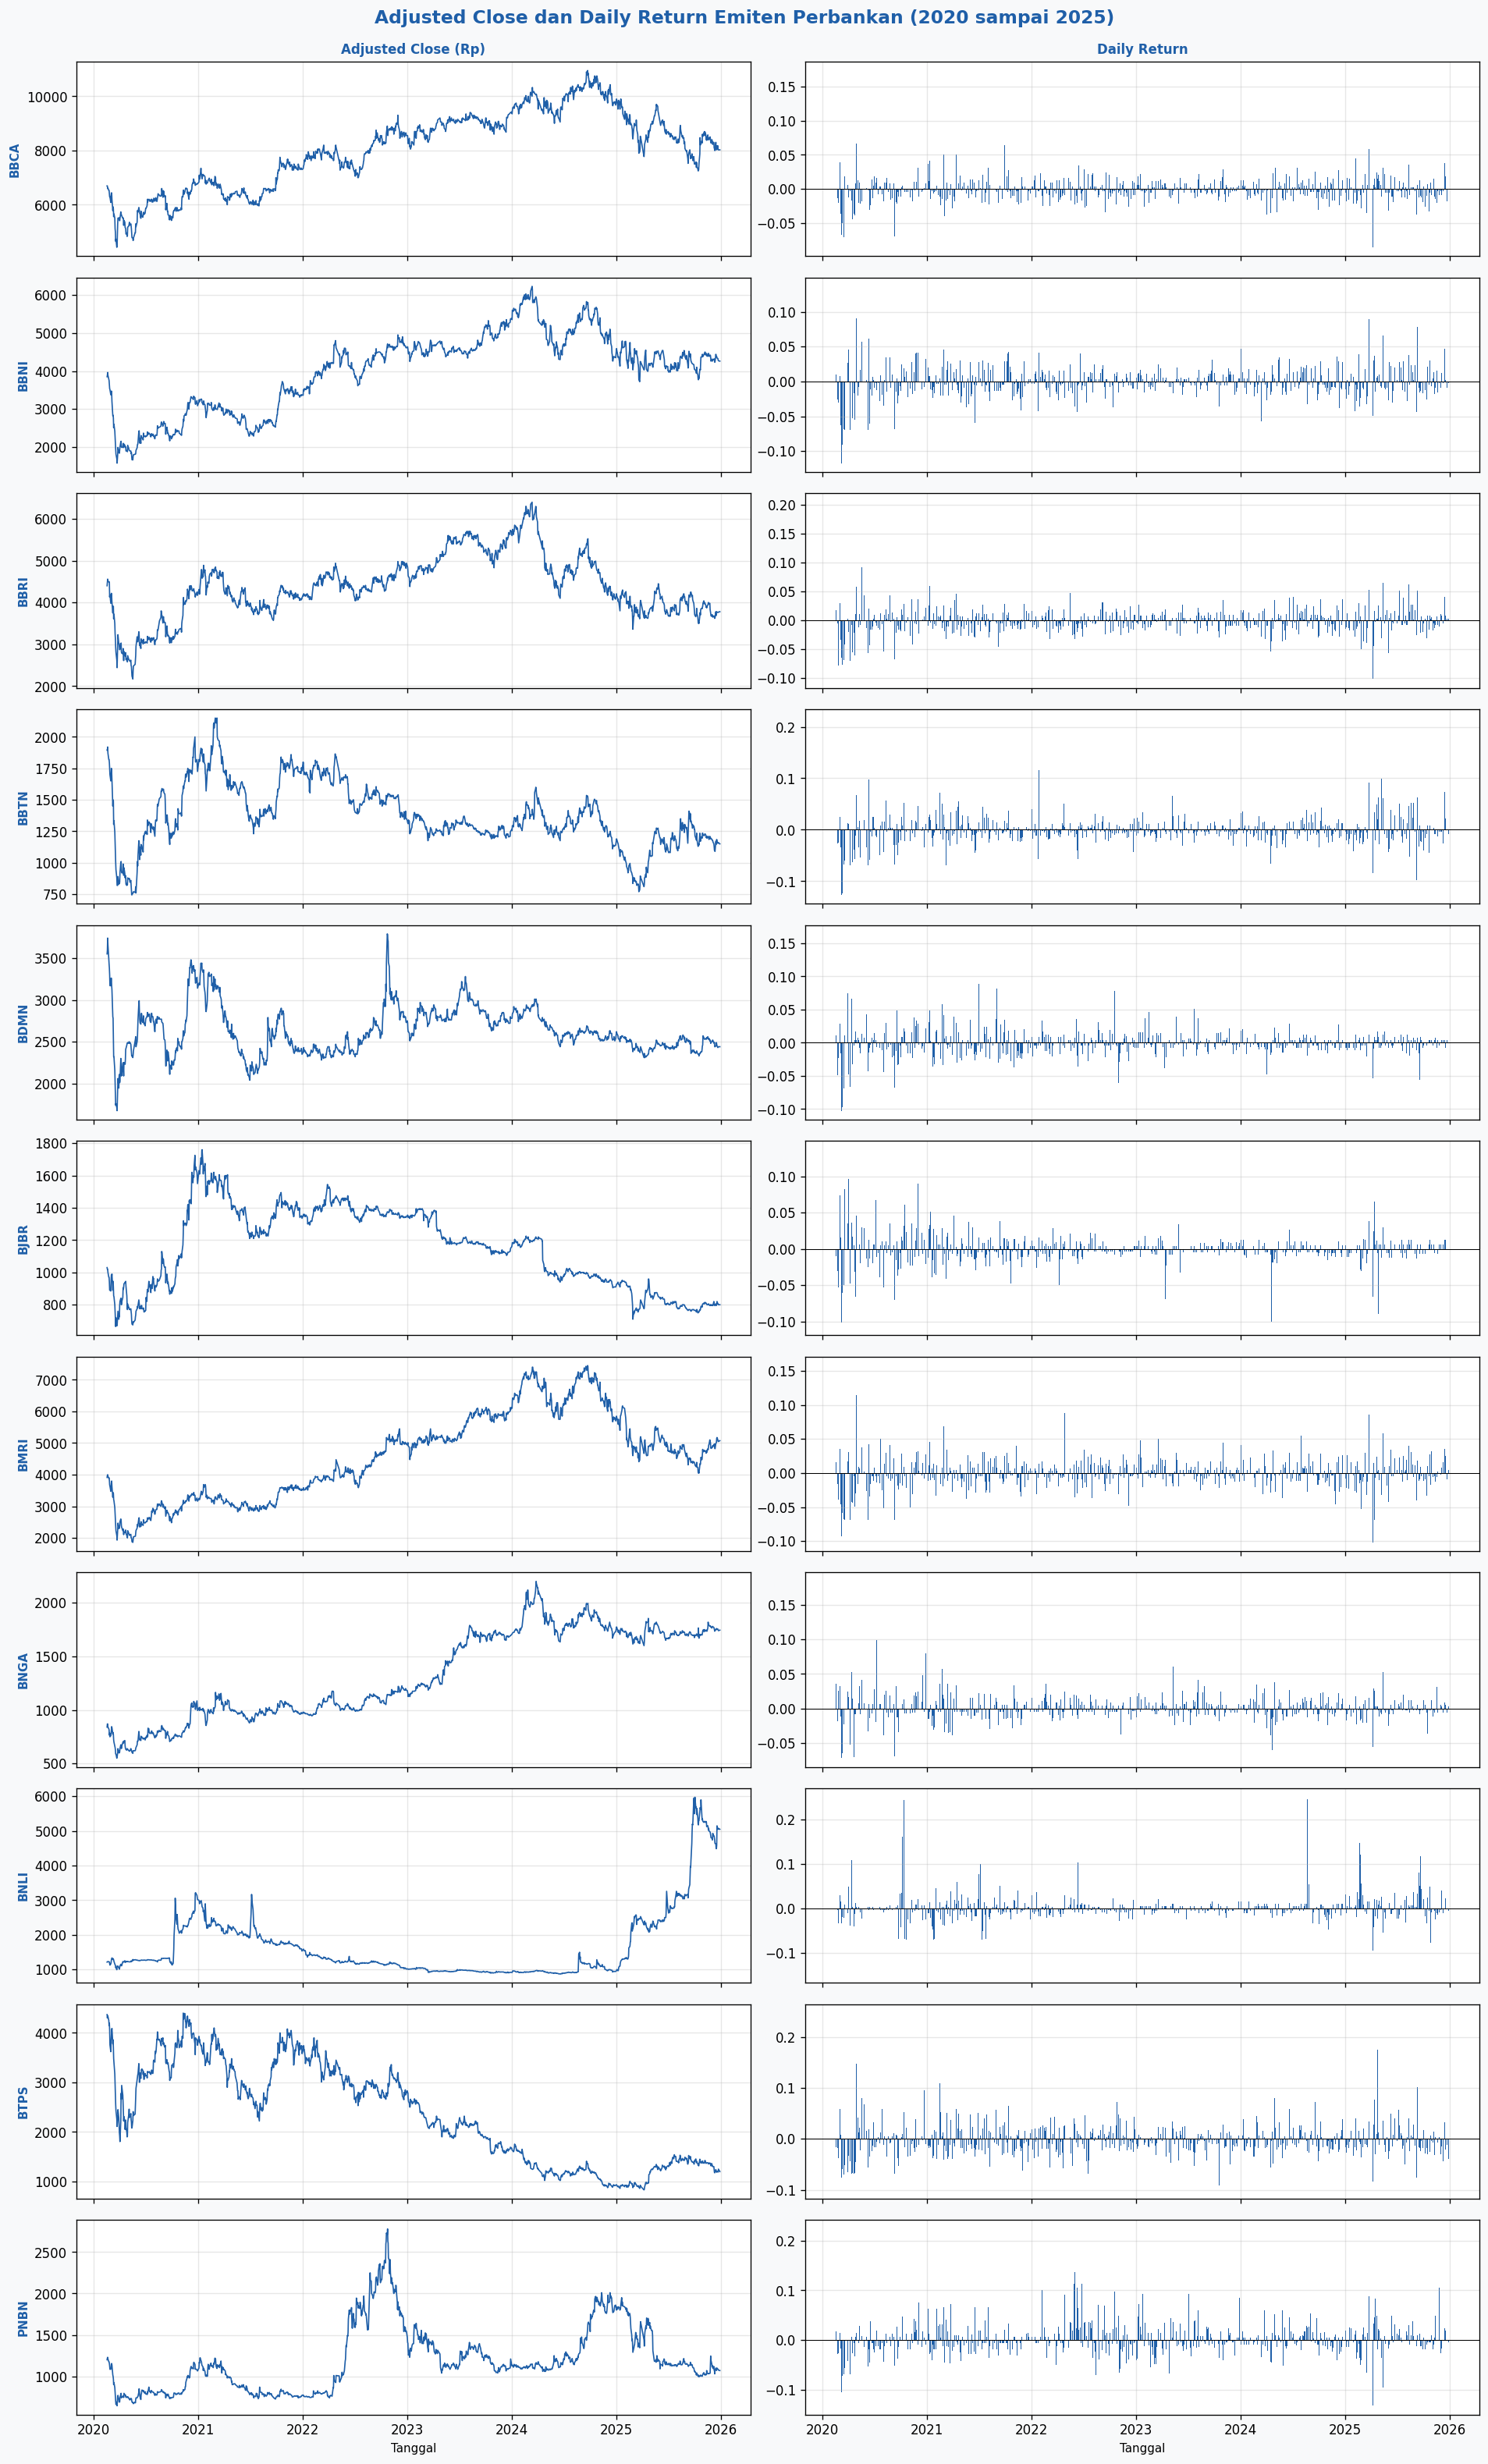

In [11]:
# grafik harga dan return harian 11 saham dari 2020 sampai 2025
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

blue = "#1F5FA8"

# daftar saham diambil lagi dari data, isinya tetap 11 saham
tickers = sorted(clean_fe_df["Kode Saham"].unique())   # 11 emiten
n = len(tickers)

fig, axes = plt.subplots(
    n, 2, figsize=(16, 2.4 * n), facecolor="#F8F9FA", sharex=True
)
fig.suptitle(
    "Adjusted Close dan Daily Return Emiten Perbankan (2020 sampai 2025)",
    fontsize=14,
    fontweight="bold",
    color=blue,
    y=0.995,
)

# satu baris grafik untuk tiap saham
for row, ticker in enumerate(tickers):
    stock = (
        clean_fe_df[clean_fe_df["Kode Saham"] == ticker]
        .sort_values("snapshot_date")
        .copy()
    )
    # daily return dari adjusted close (nilai asli, bukan persen)
    stock["daily_return"] = stock["close_adj"].pct_change()

    # kolom 1: adjusted close
    ax_price = axes[row, 0]
    ax_price.plot(stock["snapshot_date"], stock["close_adj"], color=blue, linewidth=1.0)
    ax_price.set_ylabel(ticker, fontsize=9, fontweight="bold", color=blue)
    ax_price.grid(alpha=0.3)

    # kolom 2: daily return sebagai bar dari garis nol
    ax_ret = axes[row, 1]
    ax_ret.bar(
        stock["snapshot_date"],
        stock["daily_return"],
        color=blue,
        width=1.0,
        linewidth=0,
    )
    ax_ret.axhline(0, color="black", linewidth=0.6)
    ax_ret.grid(alpha=0.3)

    if row == 0:
        ax_price.set_title("Adjusted Close (Rp)", fontsize=10, fontweight="bold", color=blue)
        ax_ret.set_title("Daily Return", fontsize=10, fontweight="bold", color=blue)

# label tahun cuma di grafik paling bawah
for ax in axes[-1]:
    ax.set_xlabel("Tanggal", fontsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

## Simpan Hasil Preprocessing

Data dengan fitur dan target lengkap disimpan ke panel_features.parquet untuk pemodelan. Tabel berikut merangkum file hasil preprocessing beserta jumlah barisnya.

In [12]:
# menyimpan data fitur dan target buat notebook 03
clean_fe_df.to_parquet(processed_dir / "panel_features.parquet", index=False)
output_summary = pd.DataFrame(
    {
        "File": [
            "panel_features.parquet",
            "panel_calendar.parquet",
            "panel_adjusted_prices.parquet",
        ],
        "Baris": [
            len(clean_fe_df),
            len(calendar_data),
            len(calendar_data),
        ],
    }
)
show_table(output_summary)

,File,Baris
0,panel_features.parquet,"15,543"
1,panel_calendar.parquet,"15,917"
2,panel_adjusted_prices.parquet,"15,917"
